In [103]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [104]:
# Load and store the MNIST dataset split
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

# Display shapes to confirm
print(f"Training set: X_train shape={X_train.shape}, y_train shape={y_train.shape}")
print(f"Testing set:  X_test shape={X_test.shape}, y_test shape={y_test.shape}")

Training set: X_train shape=(60000, 28, 28), y_train shape=(60000,)
Testing set:  X_test shape=(10000, 28, 28), y_test shape=(10000,)


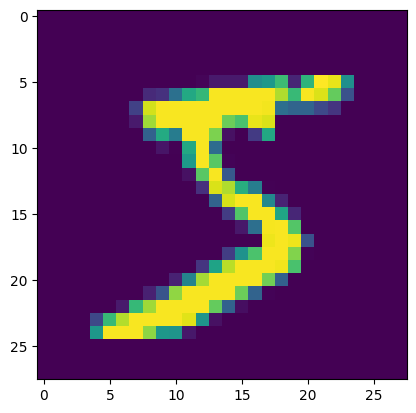

In [105]:
import matplotlib.pyplot as plt

plt.imshow(X_train[0])

In [113]:
print(X_train[0].shape)
print(X_test[0].shape)

print(X_train.shape)
print(X_train.shape)

print(y_train.shape)
print(y_test.shape)

(28, 28)
(28, 28)
(60000, 28, 28)
(60000, 28, 28)
(60000,)
(10000,)


In [114]:
# Normalize only the training features, keeping the integer labels untouched
X_train = X_train / 255.0
X_test = X_test / 255.0

In [115]:
print(X_train[0].shape)
print(X_test[0].shape)

print(X_train.shape)
print(X_train.shape)

print(y_train.shape)
print(y_test.shape)

(28, 28)
(28, 28)
(60000, 28, 28)
(60000, 28, 28)
(60000,)
(10000,)


In [116]:
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [117]:
X_train = X_train.reshape((X_train.shape[0], 28*28))
X_test = X_test.reshape((X_test.shape[0], 28*28))

In [120]:
print(X_train[0].shape)
print(X_test[0].shape)

print(X_train.shape)
print(X_train.shape)

print(y_train.shape)
print(y_test.shape)

(784,)
(784,)
(60000, 784)
(60000, 784)
(60000,)
(10000,)


In [121]:
X_train[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [122]:
model = Sequential()

model.add(Dense(128, activation='relu', input_dim=784))
model.add(Dense(32, activation='relu'))
model.add(Dense(10, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [123]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,938 (409.91 KB)

 Trainable params: 104,938 (409.91 KB)

 Non-trainable params: 0 (0.00 B)

In [124]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [125]:
history = model.fit(X_train, y_train, epochs=15, validation_split=0.2)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9190 - loss: 0.2821 - val_accuracy: 0.9579 - val_loss: 0.1480
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9636 - loss: 0.1196 - val_accuracy: 0.9651 - val_loss: 0.1139
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9749 - loss: 0.0821 - val_accuracy: 0.9704 - val_loss: 0.1052
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9808 - loss: 0.0615 - val_accuracy: 0.9729 - val_loss: 0.0900
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9847 - loss: 0.0471 - val_accuracy: 0.9736 - val_loss: 0.0985
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 4ms/step - accuracy: 0.9881 - loss: 0.0374 - val_accuracy: 0.9718 - val_loss: 0.1019
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9905 - loss: 0.0307 - val_accuracy: 0.9723 - val_loss: 0.1031
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9913 - loss: 0.0254

In [126]:
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(60000, 784)
(10000, 784)
(60000,)
(10000,)


In [127]:
y_prob = model.predict(X_test)
y_pred = y_prob.argmax(axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [128]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.9769

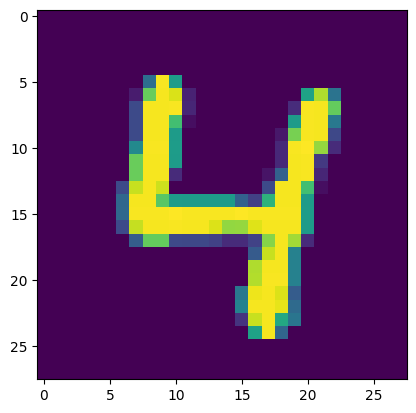

In [138]:
plt.imshow(X_test[56].reshape(28, 28))

In [143]:
print(X_test[56].shape)
print(X_test[55].shape)

(784,)
(784,)


In [144]:
# Slicing with [55:56] keeps the batch dimension, resulting in shape (1, 784)
model.predict(X_test[56].reshape(1, 784)).argmax()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step


np.int64(4)

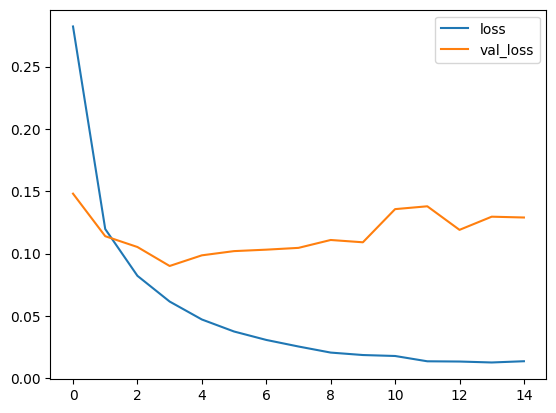

In [145]:
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend()

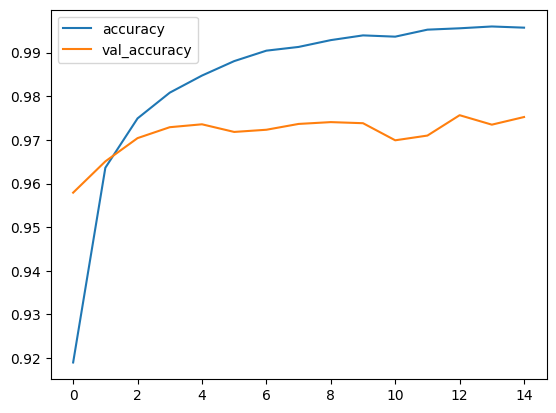

In [146]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.legend()